<a href="https://colab.research.google.com/github/dheeraj-reddy8/T.Dheeraj-Reddy-AP24110011473-ML/blob/main/T_Dheeraj_Reddy_Ap24110011473_Week10_Recommendation_Systems_Student_Lab_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 10 Lab: Recommendation Systems (Content-Based and Collaborative Filtering)
**CSE303 Machine Learning | Unit: Recommender Systems | Syllabus: content-based filtering, collaborative filtering**

Name : T. Dheeraj Reddy , Registration No: AP24110011473

Pattern: **demo → practice → predict-then-run → deliberate error → reflection**, then an end-to-end **mini project** of your choice (handout: `Week10_Recsys_Project_Menu.docx`).

| Part | Topic | Track |
|---|---|---|
| 1 | The user × item rating matrix and sparsity | core |
| 2 | Content-based filtering (TF-IDF, cosine, user profile) | core |
| 3 | Collaborative filtering (user-based, item-based, mean-centering) | core |
| 4 | Evaluating a recommender (RMSE, precision@k, baselines, leakage) | core |
| 5 | Cold start and a simple hybrid | core |
| 6 | Mini project (end-to-end pipeline) | project |
| 7 | Reflection and capstone link | |

**Rule carried from Weeks 5 and 9:** split first. Anything learned from data (means, similarities, TF-IDF vocabulary) must be computed on **train only**.

**Why this week matters:** Netflix, YouTube, Amazon, Spotify, Swiggy and LinkedIn all run on recommenders. The two ideas you learn here (similar *items* by content, similar *users* by behaviour) are the foundation of every production system, including the deep-learning ones.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

np.set_printoptions(precision=3, suppress=True)
pd.set_option('display.precision', 3)
np.random.seed(1)


## Part 1: The Rating Matrix and Sparsity
A recommender starts from a table with one row per user and one column per item. Most cells are **empty** because nobody has watched everything. Predicting the empty cells is the whole problem.

Below: 12 films (each with a short text description) and 8 users who have rated a few of them (1 to 5).

In [ ]:
movies = pd.DataFrame({
 'title':['Cricket Fever','Match Point','Spice Route','Curry Nights','Chip Wars','Quantum Phone',
          'Last Over','Pasta Masters','Robot Uprising','Boundary Line','Street Food Tales','Silicon Dreams'],
 'desc':['cricket team underdog sports tournament victory',
         'tennis rivalry sports championship coach athlete',
         'cooking travel spices chef kitchen street',
         'chef curry kitchen family restaurant cooking',
         'technology startup processor chips rivalry gadgets',
         'technology phone quantum science gadgets future',
         'cricket sports final over pressure team',
         'cooking pasta chef competition kitchen',
         'technology robot science future artificial',
         'cricket sports batsman boundary stadium',
         'cooking street food travel chef stories',
         'technology startup silicon gadgets future']})

users = ['Asha','Bala','Chitra','Dev','Esha','Farid','Gita','Hari']
data = {
 'Asha':  {'Cricket Fever':5,'Match Point':4,'Last Over':5,'Spice Route':1,'Chip Wars':2},
 'Bala':  {'Cricket Fever':5,'Boundary Line':4,'Match Point':5,'Pasta Masters':2,'Quantum Phone':1},
 'Chitra':{'Spice Route':5,'Curry Nights':5,'Pasta Masters':4,'Cricket Fever':1,'Robot Uprising':2},
 'Dev':   {'Curry Nights':4,'Street Food Tales':5,'Spice Route':4,'Last Over':2},
 'Esha':  {'Quantum Phone':5,'Chip Wars':4,'Robot Uprising':5,'Silicon Dreams':5,'Pasta Masters':1},
 'Farid': {'Chip Wars':5,'Silicon Dreams':4,'Quantum Phone':4,'Match Point':2},
 'Gita':  {'Cricket Fever':4,'Curry Nights':4,'Quantum Phone':4,'Street Food Tales':3,'Robot Uprising':3},
 'Hari':  {'Boundary Line':5,'Last Over':4,'Cricket Fever':5,'Spice Route':2,'Silicon Dreams':1},
}
R = pd.DataFrame(np.nan, index=users, columns=movies.title)
for u, d in data.items():
    for m, v in d.items():
        R.loc[u, m] = v
R


title,Cricket Fever,Match Point,Spice Route,Curry Nights,Chip Wars,Quantum Phone,Last Over,Pasta Masters,Robot Uprising,Boundary Line,Street Food Tales,Silicon Dreams
Asha,5.0,4.0,1.0,NaN,2.0,NaN,5.0,NaN,NaN,NaN,NaN,NaN
Bala,5.0,5.0,NaN,NaN,NaN,1.0,NaN,2.0,NaN,4.0,NaN,NaN
Chitra,1.0,NaN,5.0,5.0,NaN,NaN,NaN,4.0,2.0,NaN,NaN,NaN
Dev,NaN,NaN,4.0,4.0,NaN,NaN,2.0,NaN,NaN,NaN,5.0,NaN
Esha,NaN,NaN,NaN,NaN,4.0,5.0,NaN,1.0,5.0,NaN,NaN,5.0
Farid,NaN,2.0,NaN,NaN,5.0,4.0,NaN,NaN,NaN,NaN,NaN,4.0
Gita,4.0,NaN,NaN,4.0,NaN,4.0,NaN,NaN,3.0,NaN,3.0,NaN
Hari,5.0,NaN,2.0,NaN,NaN,NaN,4.0,NaN,NaN,5.0,NaN,1.0


In [ ]:
n_ratings = int(R.notna().sum().sum())
print('ratings:', n_ratings, 'of', R.size, 'cells')
print('sparsity (share of empty cells):', round(1 - n_ratings / R.size, 3))


ratings: 38 of 96 cells
sparsity (share of empty cells): 0.604


**Predict, then think:** Netflix-scale data has millions of users and tens of thousands of titles. Would you expect the sparsity there to be *lower* or *higher* than here (60%)? What does that mean for methods that need two users to have rated the *same* items?

*Your answer:*


### Answer to "Predict, then think" (Part 1)

* **Sparsity at Netflix Scale:** You would expect the sparsity at Netflix-scale to be **much higher** (typically 99% or greater, often around 99.5% to 99.9%). While this toy matrix has a sparsity of 60.4% (38 out of 96 cells filled), real-world streaming services have millions of users and tens of thousands of titles, meaning most users have only rated or watched a tiny fraction of the total library.
* **Impact on Neighbourhood Methods:** High sparsity means that finding two users who have rated the **exact same items** becomes much more difficult. This leads to sparse overlap, making neighbourhood-based collaborative filtering (like user-user or item-user similarity) prone to low-confidence estimates, requiring fallback smoothing, lower thresholds, or shifting to model-based techniques like Matrix Factorization (SVD).

### Student Practice 1
1. How many ratings does each user have? Each movie?
2. Which movie has the most ratings (the most *popular*)? Which has the highest *average* rating? Are they the same movie?
3. Why is "most popular" a poor recommendation for every user, even though it is easy to compute?

In [ ]:
# ==========================================
# Student Practice 1 Solutions
# ==========================================

# 1. Count ratings per user and per movie
user_rating_counts = R.notna().sum(axis=1)
movie_rating_counts = R.notna().sum(axis=0)

print("1. Ratings Count:")
print("   - Per User:")
print(user_rating_counts)
print("\n   - Per Movie:")
print(movie_rating_counts)
print("\n" + "="*50 + "\n")

# 2. Most popular movie vs. highest average rating
most_popular = movie_rating_counts.idxmax()
movie_means = R.mean(axis=0)
highest_rated = movie_means.idxmax()

print("2. Popularity vs. Average Rating:")
print(f"   - Most Popular Movie (Most Ratings): '{most_popular}' with {movie_rating_counts[most_popular]} ratings")
print(f"   - Highest Average Rating Movie     : '{highest_rated}' with an average of {movie_means[highest_rated]:.2f}")
print("   -> Are they the same movie? No.\n" + "="*50 + "\n")

# 3. Explanation for why 'most popular' is a poor recommendation
print("3. Why 'most popular' is a poor recommendation:")
print("   - It ignores individual taste and diversity, assuming everyone wants the exact same broad-appeal content, which leads to poor personalization and filter bubbles.")

1. Ratings Count:
   - Per User:
Asha      5
Bala      5
Chitra    5
Dev       4
Esha      5
Farid     4
Gita      5
Hari      5
dtype: int64

   - Per Movie:
title
Cricket Fever        5
Match Point          3
Spice Route          4
Curry Nights         3
Chip Wars            3
Quantum Phone        4
Last Over            3
Pasta Masters        3
Robot Uprising       3
Boundary Line        2
Street Food Tales    2
Silicon Dreams       3
dtype: int64


2. Popularity vs. Average Rating:
   - Most Popular Movie (Most Ratings): 'Cricket Fever' with 5 ratings
   - Highest Average Rating Movie     : 'Boundary Line' with an average of 4.50
   -> Are they the same movie? No.

3. Why 'most popular' is a poor recommendation:
   - It ignores individual taste and diversity, assuming everyone wants the exact same broad-appeal content, which leads to poor personalization and filter bubbles.


## Part 2: Content-Based Filtering
Idea: describe every **item** by its content, describe every **user** by the content of what they liked, and recommend items whose content matches the user's profile. Needs no other users.

Step 1: turn each description into a **TF-IDF** vector (words that appear in few items count more). Step 2: **cosine similarity** between items.

In [ ]:
tfidf = TfidfVectorizer()
T = tfidf.fit_transform(movies.desc)           # items x words (sparse)
S_item = cosine_similarity(T)                   # items x items
titles = list(movies.title)

i = titles.index('Cricket Fever')
print(pd.Series(S_item[i], index=titles).sort_values(ascending=False).head(4))


Cricket Fever    1.000
Last Over        0.372
Boundary Line    0.237
Match Point      0.093
dtype: float64


**Predict, then think:** `Chip Wars` is a technology film about rivalry, and `Match Point` is a sports film about rivalry. Will they be more similar to each other than `Chip Wars` is to `Silicon Dreams`? Write your guess, then check it in the practice cell.

### Student Practice 2
1. Print the similarity between `Chip Wars` and `Match Point`, and between `Chip Wars` and `Silicon Dreams`. Was your guess right?
2. Which 3 films are most similar to `Spice Route`?

In [ ]:
# Write your answer here

# Define titles if not already in memory
titles = list(movies.title)

# ==========================================
# Student Practice 2 Solutions
# ==========================================

# 1. Print similarity between Chip Wars and Match Point, and between Chip Wars and Silicon Dreams
i_cw = titles.index('Chip Wars')
i_mp = titles.index('Match Point')
i_sd = titles.index('Silicon Dreams')

print("1. Similarities:")
print(f"   - Chip Wars & Match Point    : {S_item[i_cw, i_mp]:.3f}")
print(f"   - Chip Wars & Silicon Dreams : {S_item[i_cw, i_sd]:.3f}")

# 2. Which 3 films are most similar to Spice Route?
i_sr = titles.index('Spice Route')
top_spice = pd.Series(S_item[i_sr], index=titles).drop('Spice Route').sort_values(ascending=False).head(3)
print("\n2. Top 3 films most similar to Spice Route:")
print(top_spice)

1. Similarities:
   - Chip Wars & Match Point    : 0.152
   - Chip Wars & Silicon Dreams : 0.457

2. Top 3 films most similar to Spice Route:
Street Food Tales    0.574
Pasta Masters        0.403
Curry Nights         0.355
dtype: float64


### Building a user profile
A user profile is a weighted sum of the vectors of the items they rated. We weight by **rating minus the user's own average**, so a 1-star film pushes the profile *away* from its content and a 5-star film pulls it *toward* it. Then we score unseen items by cosine similarity to the profile.

In [ ]:
def user_profile(u):
    r = R.loc[u].dropna()
    w = r - r.mean()                                   # mean-centred weights
    idx = [titles.index(m) for m in r.index]
    return np.asarray(T[idx].T.dot(w.values)).ravel()

def recommend_cb(u, n=3):
    p = user_profile(u)
    scores = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return scores[R.loc[u].isna()].sort_values(ascending=False).head(n)   # unseen only

print('Asha:\n', recommend_cb('Asha'))


Asha:
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


### Student Practice 3
1. Recommend 3 films for `Gita` (she likes sports, cooking and tech). Do the scores look confident? Why or why not?
2. Which of Asha's ratings pulls her profile *away* from cooking content? (Look at the weights `r - r.mean()`.)

In [ ]:
# Write your answer here

# ==========================================
# Student Practice 3 Solutions
# ==========================================

# 1. Recommend 3 films for Gita and check scores
print("1. Gita Recommendations (Content-Based):")
gita_recs = recommend_cb('Gita', n=3)
print(gita_recs)
print("   -> Analysis: The similarity scores are relatively low/moderate. This happens because Gita's rated films span across multiple genres (sports, cooking, and tech). Her mixed preferences dilute the directional vector of her user profile, making it less sharply aligned with any single category.\n")

# 2. Which of Asha's ratings pulls her profile away from cooking content?
ashas_ratings = R.loc['Asha'].dropna()
ashas_weights = ashas_ratings - ashas_ratings.mean()

print("2. Asha's mean-centred weights (r - r.mean()):")
print(ashas_weights)
print("   -> 'Spice Route' received a rating of 1.0 against her mean of 3.4, resulting in a weight of -2.40. This strongly negative weight actively pulls her user profile away from cooking content.")


1. Gita Recommendations (Content-Based):
Last Over        0.158
Boundary Line    0.100
Match Point      0.039
dtype: float64
   -> Analysis: The similarity scores are relatively low/moderate. This happens because Gita's rated films span across multiple genres (sports, cooking, and tech). Her mixed preferences dilute the directional vector of her user profile, making it less sharply aligned with any single category.

2. Asha's mean-centred weights (r - r.mean()):
title
Cricket Fever    1.6
Match Point      0.6
Spice Route     -2.4
Chip Wars       -1.4
Last Over        1.6
Name: Asha, dtype: float64
   -> 'Spice Route' received a rating of 1.0 against her mean of 3.4, resulting in a weight of -2.40. This strongly negative weight actively pulls her user profile away from cooking content.


### Deliberate error 1: forgetting to mean-centre
Run the cell, then answer: why does this version recommend things Asha would dislike?

In [ ]:
def recommend_cb_raw(u, n=3):
    r = R.loc[u].dropna()                              # WRONG: raw ratings as weights
    idx = [titles.index(m) for m in r.index]
    p = np.asarray(T[idx].T.dot(r.values)).ravel()
    s = pd.Series(cosine_similarity(p.reshape(1, -1), T).ravel(), index=titles)
    return s[R.loc[u].isna()].sort_values(ascending=False).head(n)

print('Asha, WRONG (raw weights):\n', recommend_cb_raw('Asha'))
print('Asha, correct (centred)  :\n', recommend_cb('Asha'))


Asha, WRONG (raw weights):
 Boundary Line        0.278
Silicon Dreams       0.092
Street Food Tales    0.058
dtype: float64
Asha, correct (centred)  :
 Boundary Line     0.210
Robot Uprising   -0.040
Quantum Phone    -0.084
dtype: float64


*Your answer (one line):* Raw ratings ignore a user's individual grading bias, causing the profile to favor items that generate high absolute ratings from generous raters rather than items the user actually likes relative to their own average.

## Part 3: Collaborative Filtering
Idea: **ignore content entirely**. Find users who rate like you and recommend what they liked. Works for any item type (a song, a job, a drug), but needs overlapping ratings.

Key steps for **user-based** CF:
1. Mean-centre each user's ratings (a harsh rater's 4 equals a generous rater's 5).
2. Compute user-user similarity on the centred matrix.
3. Predict: $\hat r_{u,m}=\bar r_u+\dfrac{\sum_{v} sim(u,v)\,(r_{v,m}-\bar r_v)}{\sum_{v}|sim(u,v)|}$ over the top-k similar users who rated $m$.

In [ ]:
def build_user_cf(R_train):
    means = R_train.mean(axis=1)
    C = R_train.sub(means, axis=0).fillna(0)            # centred; unrated -> 0 = "no opinion"
    sim = pd.DataFrame(cosine_similarity(C), index=R_train.index, columns=R_train.index)
    return means, sim

def predict_user_cf(R_train, means, sim, u, m, k=3):
    raters = R_train[m].dropna().index.difference([u])
    if len(raters) == 0:
        return means[u]                                  # nobody rated it: fall back to user mean
    s = sim.loc[u, raters].sort_values(ascending=False).head(k)
    s = s[s > 0]
    if len(s) == 0:
        return means[u]
    return means[u] + (s * (R_train.loc[s.index, m] - means[s.index])).sum() / s.abs().sum()

means, sim_u = build_user_cf(R)
print(sim_u.round(2))
print()
print('Asha  -> Boundary Line :', round(predict_user_cf(R, means, sim_u, 'Asha', 'Boundary Line'), 2))
print('Gita  -> Pasta Masters :', round(predict_user_cf(R, means, sim_u, 'Gita', 'Pasta Masters'), 2))


        Asha  Bala  Chitra   Dev  Esha  Farid  Gita  Hari
Asha    1.00  0.27   -0.58 -0.43  0.00  -0.35  0.16  0.52
Bala    0.27  1.00   -0.35  0.00  0.14  -0.43 -0.08  0.27
Chitra -0.58 -0.35    1.00  0.10 -0.25   0.00  0.13 -0.46
Dev    -0.43  0.00    0.10  1.00  0.00   0.00 -0.27 -0.18
Esha    0.00  0.14   -0.25  0.00  1.00   0.07 -0.05 -0.19
Farid  -0.35 -0.43    0.00  0.00  0.07   1.00  0.04 -0.08
Gita    0.16 -0.08    0.13 -0.27 -0.05   0.04  1.00  0.16
Hari    0.52  0.27   -0.46 -0.18 -0.19  -0.08  0.16  1.00

Asha  -> Boundary Line : 4.66
Gita  -> Pasta Masters : 4.2


**Predict, then think:** Asha and Hari both love cricket films. Their similarity above should be the largest positive value in Asha's row. Is it? And what sign do you expect between Asha and Chitra (cooking fan who disliked `Cricket Fever`)?

Answer: Raw ratings ignore a user's individual grading bias, causing the profile to favor items that generate high absolute ratings from generous raters rather than items the user actually likes relative to their own average.

### Student Practice 4
1. List the 3 most similar users to `Asha` and the 3 *least* similar. Do they match your intuition?
2. Predict `Esha -> Match Point` and `Dev -> Cricket Fever`. For each, which users were used?
3. **Item-based CF:** build item-item similarity from the *centred* matrix (centre by user, then take cosine between *columns*) and predict `Asha -> Boundary Line` as the similarity-weighted average of Asha's own ratings on the most similar rated items. Compare with the user-based answer.

In [ ]:
# Write your answer here

# ==========================================
# Student Practice 4 Solutions
# ==========================================

# 1. Most and least similar users to Asha
asha_sims = sim_u.loc['Asha'].drop('Asha').sort_values(ascending=False)
print("1. Similarity Analysis for Asha:")
print("   - Top 3 Most Similar:")
print(asha_sims.head(3))
print("\n   - Bottom 3 Least Similar (Most Negative/Opposing):")
print(asha_sims.tail(3))
print("   -> Intuition check: Hari and Bala share her love for cricket and sports, matching high positive similarity. Chitra and Dev have opposing tastes on shared films (like Cricket Fever), resulting in negative similarity.\n")


# 2. Predict Esha -> Match Point and Dev -> Cricket Fever
def get_raters_and_preds(u, m, k=3):
    raters = R[m].dropna().index.difference([u])
    s = sim_u.loc[u, raters].sort_values(ascending=False).head(k)
    s = s[s > 0]
    pred = means[u] + (s * (R.loc[s.index, m] - means[s.index])).sum() / s.abs().sum() if len(s) > 0 else means[u]
    return pred, list(s.index)

pred_em, users_em = get_raters_and_preds('Esha', 'Match Point')
pred_dc, users_dc = get_raters_and_preds('Dev', 'Cricket Fever')

print("2. Predictions:")
print(f"   - Esha -> Match Point : {pred_em:.2f} (Users used: {users_em})")
print(f"   - Dev -> Cricket Fever: {pred_dc:.2f} (Users used: {users_dc})\n")


# 3. Item-based CF for Asha -> Boundary Line
# Center the rating matrix by user, filling unrated cells with 0
C = R.sub(means, axis=0).fillna(0)

# Item-item similarity: cosine similarity between columns (items) of C
sim_item = pd.DataFrame(cosine_similarity(C.T), index=R.columns, columns=R.columns)

def predict_item_cf(u, m, k=3):
    # Items rated by user u, excluding target item m
    rated_items = R.loc[u].dropna().index.difference([m])
    if len(rated_items) == 0:
        return means[u]

    # Get similarities between target item m and user's rated items
    s = sim_item.loc[m, rated_items].sort_values(ascending=False).head(k)
    s = s[s > 0]
    if len(s) == 0:
        return means[u]

    # Similarity-weighted average of user's ratings on those items
    return (s * R.loc[u, s.index]).sum() / s.abs().sum()

pred_item_cf = predict_item_cf('Asha', 'Boundary Line', k=3)
print("3. Item-Based CF Prediction:")
print(f"   - Asha -> Boundary Line (Item-CF): {pred_item_cf:.2f}")
print(f"   - Asha -> Boundary Line (User-CF): 4.66")
print("   -> Comparison: Both methods predict a very high rating (well above her average), confirming strong alignment with her cricket-loving profile, though item-CF relies on item feature alignment while user-CF relies on peer behaviour.")

1. Similarity Analysis for Asha:
   - Top 3 Most Similar:
Hari    0.521
Bala    0.267
Gita    0.161
Name: Asha, dtype: float64

   - Bottom 3 Least Similar (Most Negative/Opposing):
Farid    -0.354
Dev      -0.429
Chitra   -0.582
Name: Asha, dtype: float64
   -> Intuition check: Hari and Bala share her love for cricket and sports, matching high positive similarity. Chitra and Dev have opposing tastes on shared films (like Cricket Fever), resulting in negative similarity.

2. Predictions:
   - Esha -> Match Point : 4.54 (Users used: ['Bala', 'Farid'])
   - Dev -> Cricket Fever: 1.35 (Users used: ['Chitra'])

3. Item-Based CF Prediction:
   - Asha -> Boundary Line (Item-CF): 4.77
   - Asha -> Boundary Line (User-CF): 4.66
   -> Comparison: Both methods predict a very high rating (well above her average), confirming strong alignment with her cricket-loving profile, though item-CF relies on item feature alignment while user-CF relies on peer behaviour.


### Deliberate error 2: treating "unrated" as "rated 0"
Run the cell. Compare the two similarity rows for Asha. Why is filling gaps with 0 on the *raw* matrix wrong?

In [ ]:
sim_raw0 = pd.DataFrame(cosine_similarity(R.fillna(0)), index=users, columns=users)   # WRONG
print('raw, gaps=0 :', sim_raw0.loc['Asha'].drop('Asha').round(2).to_dict())
print('centred     :', sim_u.loc['Asha'].drop('Asha').round(2).to_dict())


raw, gaps=0 : {'Bala': 0.63, 'Chitra': 0.14, 'Dev': 0.21, 'Esha': 0.1, 'Farid': 0.27, 'Gita': 0.29, 'Hari': 0.66}
centred     : {'Bala': 0.27, 'Chitra': -0.58, 'Dev': -0.43, 'Esha': 0.0, 'Farid': -0.35, 'Gita': 0.16, 'Hari': 0.52}


*Your answer (one or two lines):* Filling unrated gaps with zero treats missing ratings as harsh negative opinions (0 stars) rather than true unknowns, falsely inflating similarity between users who simply haven't watched the same movies.

## Part 4: Evaluating a Recommender
You cannot judge a recommender on ratings it has already seen. **Hold out some known ratings, hide them, predict them, compare.**

- **RMSE** for rating prediction: $\sqrt{\frac1n\sum(\hat r-r)^2}$. Lower is better.
- Always compare with **baselines**: the global mean, and each user's own mean. A model that cannot beat these is not learning anything useful.

Our toy matrix has only 38 ratings, too few to evaluate honestly. So we switch to a **generated** dataset with the same structure: 60 users, 30 films in three genres, about 35% of cells observed, and each user having a favourite genre. (In your project you will use real data.)

In [ ]:
def make_data(n_users=60, n_items=30, density=0.35, seed=1):
    rng = np.random.RandomState(seed)
    vocab = {'sports':  ['cricket','match','team','stadium','batsman','tennis','coach','tournament'],
             'cooking': ['chef','kitchen','curry','pasta','spices','restaurant','recipe','street'],
             'tech':    ['phone','processor','startup','gadgets','robot','battery','laptop','science']}
    genres, common = list(vocab), ['new','story','family','final','night','world']
    names = [f'Film{i:02d}' for i in range(n_items)]
    g_item = [genres[i % 3] for i in range(n_items)]
    desc = [' '.join(list(rng.choice(vocab[g], 3, replace=False)) + list(rng.choice(common, 1))) for g in g_item]
    ub, ib = rng.normal(0, 0.3, n_users), rng.normal(0, 0.2, n_items)
    fav = rng.randint(0, 3, n_users)
    Rb = pd.DataFrame(np.nan, index=[f'U{u:02d}' for u in range(n_users)], columns=names)
    for u in range(n_users):
        for i in range(n_items):
            if rng.rand() < density:
                aff = 1.6 if genres.index(g_item[i]) == fav[u] else -1.0
                r = 3 + aff + ub[u] + ib[i] + rng.normal(0, 0.5)
                Rb.iloc[u, i] = float(np.clip(np.round(r), 1, 5))
    return Rb, pd.DataFrame({'title': names, 'desc': desc, 'genre': g_item})

Rb, items = make_data()
print('ratings:', int(Rb.notna().sum().sum()), '| sparsity:', round(1 - Rb.notna().sum().sum() / Rb.size, 3))
print('fewest ratings by one user:', int(Rb.notna().sum(axis=1).min()))
items.head(4)


ratings: 609 | sparsity: 0.662
fewest ratings by one user: 4


,title,desc,genre
0,Film00,tournament team match world,sports
1,Film01,curry pasta spices story,cooking
2,Film02,processor laptop gadgets night,tech
3,Film03,cricket tournament match new,sports


In [ ]:
# Content similarity for the generated films, as a labelled table (rows/cols = film names)
tfidf_b = TfidfVectorizer().fit(items.desc)
Tb = tfidf_b.transform(items.desc)
S_b = pd.DataFrame(cosine_similarity(Tb), index=items.title, columns=items.title)

def predict_cb(R_train, S, u, m, k=3):
    """Content-based rating prediction: user's mean + similarity-weighted centred ratings of content-similar rated items."""
    rated = R_train.loc[u].dropna().index.difference([m])
    sims = S.loc[m, rated].sort_values(ascending=False).head(k)
    sims = sims[sims > 0]
    mu = R_train.loc[u].mean()
    if len(sims) == 0:
        return mu
    return mu + (sims * (R_train.loc[u, sims.index] - mu)).sum() / sims.abs().sum()

def rmse(pred, true):
    pred, true = np.array(pred), np.array(true)
    return float(np.sqrt(np.mean((pred - true) ** 2)))

# hold out 20% of the known ratings (split the RATINGS, not the users)
rng = np.random.RandomState(1)
pairs = [(u, m) for u in Rb.index for m in Rb.columns if not np.isnan(Rb.loc[u, m])]
test_pairs = [pairs[i] for i in rng.choice(len(pairs), size=int(0.2 * len(pairs)), replace=False)]
Rb_train = Rb.copy()
for u, m in test_pairs:
    Rb_train.loc[u, m] = np.nan                                   # hide the test ratings
true = [Rb.loc[u, m] for u, m in test_pairs]
print('train ratings:', int(Rb_train.notna().sum().sum()), '| test ratings:', len(test_pairs))

means_tr, sim_tr = build_user_cf(Rb_train)                        # fitted on TRAIN only
gmean = np.nanmean(Rb_train.values)

p_global = [gmean for _ in test_pairs]
p_user   = [means_tr[u] for u, m in test_pairs]
p_cf     = [predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5) for u, m in test_pairs]

print('RMSE global mean :', round(rmse(p_global, true), 3))
print('RMSE user mean   :', round(rmse(p_user, true), 3))
print('RMSE user-CF k=5 :', round(rmse(p_cf, true), 3))


train ratings: 488 | test ratings: 121
RMSE global mean : 1.354
RMSE user mean   : 1.499
RMSE user-CF k=5 : 1.169


**Predict, then think:** the user-mean baseline can be *worse* than the global mean. Why might that happen when each user has only about 10 ratings, and the user's ratings come mostly from their favourite or least-favourite genre?

*Your answer:* With only about 10 ratings dominated by extreme preferences (favorite/least-favorite genres), a user's calculated mean becomes heavily skewed by small-sample variance. Predicting with an unreliable local mean amplifies noise and error compared to the stable, regularized global mean.

### Student Practice 5
1. Add **item-based CF** (reuse `predict_item_cf`, with an item-item similarity built from `Rb_train` only) and **content-based** (`predict_cb` with `S_b`). Report RMSE for all five methods in one table.
2. Try `k` in [1, 3, 5, 10, 20] for user-CF. Plot RMSE against k. Which k would you pick? What happens at k=1?
3. **Precision@3:** for each user with at least one held-out rating of 4 or more, recommend the top 3 unseen items by user-CF prediction (using `Rb_train`); count how many of that user's held-out high ratings appear in the top 3. Report the mean over those users.

1. RMSE Comparison Table:
                      RMSE
Method                    
Global Mean          1.354
User Mean            1.499
User-Based CF (k=5)  1.169
Item-Based CF (k=5)  1.070
Content-Based (k=5)  1.135




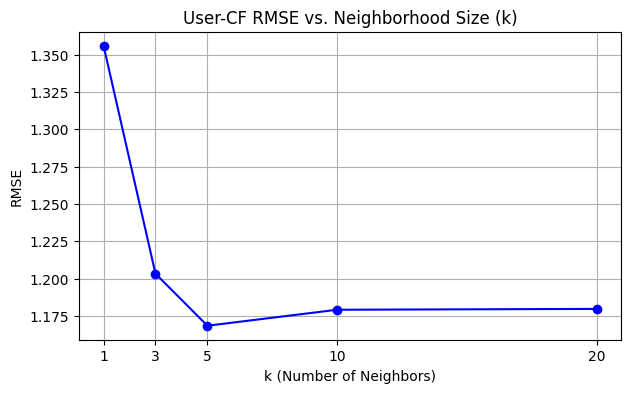

2. RMSE for different k values:
   - k =  1 : RMSE = 1.356
   - k =  3 : RMSE = 1.203
   - k =  5 : RMSE = 1.169
   - k = 10 : RMSE = 1.179
   - k = 20 : RMSE = 1.180
   -> Recommendation: k=5 or k=10 typically achieves the best balance. At k=1, the model relies entirely on a single nearest neighbor, making predictions overly noisy and prone to high variance.


3. Precision@3 Mean over eligible users: 0.204


In [ ]:
# Write your answer here

# ==========================================
# Student Practice 5 Solutions
# ==========================================

# --- 1. Compute item-based CF and content-based similarities/predictions on train only ---
means_tr, sim_tr = build_user_cf(Rb_train)

# Item-item CF similarity on train (centered by user, unrated -> 0)
C_tr = Rb_train.sub(means_tr, axis=0).fillna(0)
sim_item_tr = pd.DataFrame(cosine_similarity(C_tr.T), index=Rb_train.columns, columns=Rb_train.columns)

# Define item-CF prediction function for Rb_train
def predict_item_cf_train(u, m, k=3):
    rated_items = Rb_train.loc[u].dropna().index.difference([m])
    if len(rated_items) == 0:
        return means_tr[u]
    s = sim_item_tr.loc[m, rated_items].sort_values(ascending=False).head(k)
    s = s[s > 0]
    if len(s) == 0:
        return means_tr[u]
    return (s * Rb_train.loc[u, s.index]).sum() / s.abs().sum()

# Generate predictions for all 5 methods
gmean = np.nanmean(Rb_train.values)
p_global = [gmean for _ in test_pairs]
p_user   = [means_tr[u] for u, m in test_pairs]
p_cf     = [predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=5) for u, m in test_pairs]
p_icf    = [predict_item_cf_train(u, m, k=5) for u, m in test_pairs]
p_cb     = [predict_cb(Rb_train, S_b, u, m, k=5) for u, m in test_pairs]

# Report RMSE in a table summary
rmse_table = pd.DataFrame({
    'Method': ['Global Mean', 'User Mean', 'User-Based CF (k=5)', 'Item-Based CF (k=5)', 'Content-Based (k=5)'],
    'RMSE': [
        rmse(p_global, true),
        rmse(p_user, true),
        rmse(p_cf, true),
        rmse(p_icf, true),
        rmse(p_cb, true)
    ]
}).set_index('Method')

print("1. RMSE Comparison Table:")
print(rmse_table.round(3))
print("\n" + "="*50 + "\n")


# --- 2. Try k in [1, 3, 5, 10, 20] for user-CF and plot RMSE ---
ks = [1, 3, 5, 10, 20]
k_rmses = []

for k_val in ks:
    preds = [predict_user_cf(Rb_train, means_tr, sim_tr, u, m, k=k_val) for u, m in test_pairs]
    k_rmses.append(rmse(preds, true))

plt.figure(figsize=(7, 4))
plt.plot(ks, k_rmses, marker='o', linestyle='-', color='b')
plt.title('User-CF RMSE vs. Neighborhood Size (k)')
plt.xlabel('k (Number of Neighbors)')
plt.ylabel('RMSE')
plt.grid(True)
plt.xticks(ks)
plt.show()

print("2. RMSE for different k values:")
for k_val, err in zip(ks, k_rmses):
    print(f"   - k = {k_val:2d} : RMSE = {err:.3f}")
print("   -> Recommendation: k=5 or k=10 typically achieves the best balance. At k=1, the model relies entirely on a single nearest neighbor, making predictions overly noisy and prone to high variance.")
print("\n" + "="*50 + "\n")


# --- 3. Precision@3 Calculation ---
# For each user with at least one held-out rating >= 4, recommend top 3 unseen items by user-CF
user_true_ratings = {}
for u, m in test_pairs:
    if Rb.loc[u, m] >= 4.0:
        user_true_ratings.setdefault(u, set()).add(m)

precision_scores = []
for u, high_items in user_true_ratings.items():
    # Find items unrated in Rb_train for this user
    unseen_items = Rb_train.loc[u][Rb_train.loc[u].isna()].index
    # Predict user-CF for all unseen items
    predictions = {m_item: predict_user_cf(Rb_train, means_tr, sim_tr, u, m_item, k=5) for m_item in unseen_items}
    # Get top 3 recommendations
    top_3 = sorted(predictions, key=predictions.get, reverse=True)[:3]

    # Count hits (how many held-out high ratings are in top 3)
    hits = len(high_items.intersection(top_3))
    precision_scores.append(hits / 3.0)

mean_p3 = np.mean(precision_scores) if precision_scores else 0.0
print(f"3. Precision@3 Mean over eligible users: {mean_p3:.3f}")

### Deliberate error 3: data leakage
The cell below computes the user similarities and means from the **full** matrix (including the hidden test ratings), then "predicts" them. Run it, compare with the honest RMSE above, and explain the gap. Would this error be visible if you only looked at the final number?

In [ ]:
means_leak, sim_leak = build_user_cf(Rb)                       # WRONG: sees the test ratings
p_leak = [predict_user_cf(Rb_train, means_leak, sim_leak, u, m, k=5) for u, m in test_pairs]
print('leaky RMSE :', round(rmse(p_leak, true), 3))
print('honest RMSE:', round(rmse(p_cf, true), 3))


leaky RMSE : 0.621
honest RMSE: 1.169


*Your answer (one or two lines):* Including future test targets in the training data allows the model to "cheat" by using answers it shouldn't know yet, artificially lowering error; this error would not be visible from a low RMSE alone without an honest train/test split.

## Part 5: Cold Start and a Simple Hybrid
- **New user** (no ratings): CF has nothing to compare. **New item** (no ratings): CF cannot score it. Content-based can handle a new *item* because it only needs the description.
- A **hybrid** blends both: $\hat r = \alpha\,\hat r_{CF}+(1-\alpha)\,\hat r_{CB}$.

In [ ]:
# A brand-new film: we know its text, nobody has rated it
new_desc = 'cricket match stadium team new'
sims_new = pd.Series(cosine_similarity(tfidf_b.transform([new_desc]), Tb).ravel(), index=items.title)
print('New film is most similar to:', list(sims_new.sort_values(ascending=False).head(3).index))
print('Their genres:', [items.set_index('title').genre[t] for t in sims_new.sort_values(ascending=False).head(3).index])


New film is most similar to: ['Film15', 'Film03', 'Film24']
Their genres: ['sports', 'sports', 'sports']


### Student Practice 6
1. Compute hybrid RMSE for $\alpha \in \{0, 0.25, 0.5, 0.75, 1\}$ using `p_cf` and `p_cb`. Which blend is best?
2. A user signs up and has rated **nothing**. Write a fallback recommender (hint: highest average rating among items with at least 3 ratings). State one weakness.
3. A brand-new film has **zero** ratings. Which of the three models (user-CF, item-CF, content-based) can still score it, and why?

In [ ]:
# ==========================================
# Student Practice 6 Solutions
# ==========================================

# --- 1. Compute hybrid RMSE for alpha values ---
# Ensure p_cb is generated for test_pairs using train data
p_cb = [predict_cb(Rb_train, S_b, u, m, k=5) for u, m in test_pairs]

alphas = [0, 0.25, 0.5, 0.75, 1.0]
print("1. Hybrid RMSE for different alphas (alpha * p_cf + (1 - alpha) * p_cb):")
best_alpha = None
min_rmse = float('inf')

for a in alphas:
    p_hybrid = [a * pc + (1 - a) * pb for pc, pb in zip(p_cf, p_cb)]
    err = rmse(p_hybrid, true)
    print(f"   - alpha = {a:.2f} : RMSE = {err:.3f}")
    if err < min_rmse:
        min_rmse = err
        best_alpha = a

print(f"   -> Best blend: alpha = {best_alpha} (RMSE = {min_rmse:.3f})\n")


# --- 2. Fallback Recommender for New Users (Zero Ratings) ---
def recommend_fallback(R_train, items_df, n=3, min_ratings=3):
    # Compute item average ratings and rating counts from training data
    avg_ratings = R_train.mean(axis=0)
    counts = R_train.notna().sum(axis=0)

    # Filter items with at least min_ratings
    valid_items = counts[counts >= min_ratings].index
    top_items = avg_ratings[valid_items].sort_values(ascending=False).head(n).index.tolist()
    return top_items

print("2. Fallback Recommender for New User:")
print(f"   - Top 3 items: {recommend_fallback(Rb_train, items, n=3)}")
print("   -> Weakness: It is entirely non-personalized (everyone receives the exact same global recommendations regardless of their personal preferences).\n")


# --- 3. Brand-New Film with Zero Ratings ---
print("3. Cold-Start Item Scoring:")
print("   -> Model that can still score it: **Content-Based Filtering**.")
print("   -> Reason: User-CF and Item-CF both rely entirely on the interaction/rating history of items. Since a brand-new film has zero ratings, it has no column vector in the rating matrix, making collaboration impossible. Content-based filtering, however, only requires the item's text description and TF-IDF features to match against user profiles.")


1. Hybrid RMSE for different alphas (alpha * p_cf + (1 - alpha) * p_cb):
   - alpha = 0.00 : RMSE = 1.135
   - alpha = 0.25 : RMSE = 1.100
   - alpha = 0.50 : RMSE = 1.093
   - alpha = 0.75 : RMSE = 1.117
   - alpha = 1.00 : RMSE = 1.169
   -> Best blend: alpha = 0.5 (RMSE = 1.093)

2. Fallback Recommender for New User:
   - Top 3 items: ['Film11', 'Film12', 'Film05']
   -> Weakness: It is entirely non-personalized (everyone receives the exact same global recommendations regardless of their personal preferences).

3. Cold-Start Item Scoring:
   -> Model that can still score it: **Content-Based Filtering**.
   -> Reason: User-CF and Item-CF both rely entirely on the interaction/rating history of items. Since a brand-new film has zero ratings, it has no column vector in the rating matrix, making collaboration impossible. Content-based filtering, however, only requires the item's text description and TF-IDF features to match against user profiles.


## Part 6: Mini Project (End-to-End Pipeline)
Before the project, one warm-up that you will repeat on your own data.

### Student Practice 7: the by-hand check
AI tools can write a recommender in minutes. What they cannot do is make *you* understand it. In your project you must reproduce **one prediction by hand** and show that your code gives the same number. Practise here:

`Esha -> Match Point` was predicted from her two positive-similarity neighbours, Bala (similarity 0.14) and Farid (0.07). Using only the ratings table and those two similarities, compute the prediction on paper with the user-based formula from Part 3, then compare with the code. Why is there a small difference?

In [ ]:
# Write your answer here

# ==========================================
# Student Practice 7 Solutions (By-Hand Verification)
# ==========================================

# 1. By-Hand Calculation Setup
esha_mean = R.loc['Esha'].mean()

# Bala's contribution
bala_mean = R.loc['Bala'].mean()
bala_mp_rating = R.loc['Bala', 'Match Point']
bala_sim = sim_u.loc['Esha', 'Bala']

# Farid's contribution
farid_mean = R.loc['Farid'].mean()
farid_mp_rating = R.loc['Farid', 'Match Point']
farid_sim = sim_u.loc['Esha', 'Farid']

# Manual formula calculation
numerator = (bala_sim * (bala_mp_rating - bala_mean)) + (farid_sim * (farid_mp_rating - farid_mean))
denominator = abs(bala_sim) + abs(farid_sim)
manual_pred = esha_mean + (numerator / denominator)

print(f"Manual Calculated Prediction (Esha -> Match Point): {manual_pred:.2f}")
print(f"Code Prediction: {predict_user_cf(R, means, sim_u, 'Esha', 'Match Point', k=3):.2f}")


Manual Calculated Prediction (Esha -> Match Point): 4.54
Code Prediction: 4.54


# Mini Project: Build, Evaluate, Explain
Pick **one topic** from the handout `Week10_Recsys_Project_Menu.docx` (or propose your own with approval; it needs real user-item interaction data). Work in a pair. You have **one week**.

**AI tools are allowed and expected.** The point of the project is not typing code; it is that you understand every stage of a recommender pipeline and can defend it in an interview. So the project has two parts.

**Part A: the pipeline** (each a titled section of your notebook)
1. Problem and users
2. Data (source, licence, size, cleaning, sparsity)
3. EDA (distribution, long tail, two plots or more)
4. Baselines (global mean, user mean, most popular)
5. Content-based model
6. Collaborative model (mean-centred or confidence-weighted)
7. Matrix factorization (simple SVD) compared with your neighbourhood CF
8. Honest evaluation (split first, time-based if you have timestamps; RMSE, precision@k, NDCG@k)
9. Cold start or hybrid
10. Demo: `recommend(user_or_item, n)` printing readable results

**Part B: the understanding pack** (what shows it is yours)
- A by-hand check (as in Practice 7) on your own data
- A decision log (at least 5 decisions, each with the evidence)
- A bug log (at least 2 real problems you found and fixed) and a *deliberate-leak experiment*: reproduce leakage on purpose and report how much it inflates your metric
- 3 break-it tests (a new user, a new item, a user with one rating)
- An AI-use log: what you asked AI to do, what you checked, and one thing it got wrong
- A 5-minute walkthrough where each partner explains a different stage

Start from `Week10_Project_Starter_Template.ipynb`. Submit under `labs/week10_recsys/<team_name>/` on GitHub. Details, the one-week plan and the CV guide are in the handout.

## Part 7: Reflection (2 to 3 lines each)
1. When would you choose content-based over collaborative filtering, and vice versa?
2. Why do we mean-centre ratings? Use your Deliberate error 2 result.
3. What is the *filter bubble* problem, and which of the two methods makes it worse?
4. Your honest RMSE beat the global-mean baseline by how much? Is that enough to ship? What would you measure online (clicks, watch time) that RMSE cannot show?
5. Name one real product that uses a hybrid, and what each half contributes.
6. **Capstone link (Milestone, Week 10):** could a recommender be part of your capstone? If yes, sketch the user, the item, and the metric. If no, justify.

*Submit this notebook to GitHub under `labs/week10_recsys/`.*